# Kaplan-Meier and Nelson-Aalen estimators, with inference for quantiles

We estimate the survivor function, the cumulative hazard function and the hazard function of a sample with censored times, doing every step by hand: the life-table, the Kaplan-Meier and Nelson-Aalen estimators, their confidence intervals, and the confidence interval of a quantile (for example, the median survival time).

The data are the times, in weeks, to discontinuation of the use of an intrauterine device (IUD) for 18 women. The time is censored when the woman was still using the device the last time she was seen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from ipywidgets import interact, FloatSlider

In [2]:
ALPHA = 0.05    # Level of significance for the confidence intervals
EPSILON = 0.05  # Parameter for estimating confidence interval of a quantile

In [3]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'
opt_color   = '#E69F00'

## The data

In [4]:
DatOriginal = pd.read_csv("data/iud_discontinuation.dat", sep=r"\s+")
DatOriginal = DatOriginal.rename({'time':'Time'}, axis=1)
DatOriginal['Censored'] = (DatOriginal['status']-1)*(-1)
DatOriginal = DatOriginal.drop('status', axis=1)

In [5]:
DatOriginal

,Time,Censored
0,10,0
1,13,1
2,18,1
3,19,0
4,23,1
5,30,0
6,36,0
7,38,1
8,54,1
9,56,1


Each line is a woman. A filled point is an observed discontinuation; an open point is a censored time, we only know that the true time is larger.

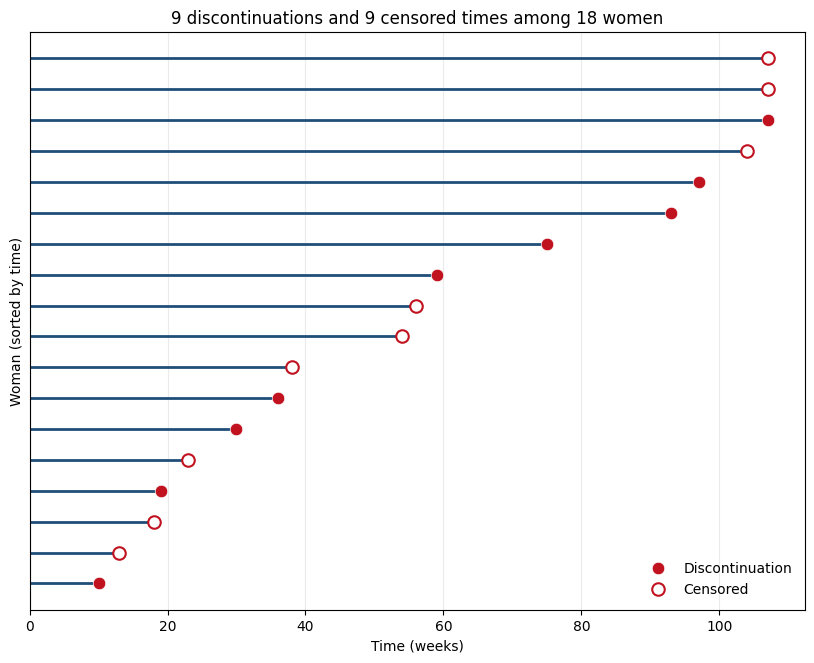

In [6]:
DatSorted = DatOriginal.sort_values(['Time', 'Censored']).reset_index(drop=True)
Observed = DatSorted['Censored'] == 0

plt.figure(figsize=(10, 7.5))
plt.hlines(DatSorted.index, 0, DatSorted['Time'], color=line_color, lw=2)
plt.plot(DatSorted.loc[Observed, 'Time'], DatSorted.index[Observed], 'o', color=point_color, markersize=9,
         markeredgecolor='white', markeredgewidth=0.5, label='Discontinuation')
plt.plot(DatSorted.loc[~Observed, 'Time'], DatSorted.index[~Observed], 'o', markerfacecolor='white', markersize=9,
         markeredgecolor=point_color, markeredgewidth=1.5, label='Censored')

plt.xlabel('Time (weeks)')
plt.ylabel('Woman (sorted by time)')
plt.yticks([])
plt.xlim(0, None)
plt.title(f'{Observed.sum()} discontinuations and {(~Observed).sum()} censored times among {len(DatSorted)} women')
plt.legend(loc='lower right', frameon=False)
plt.grid(True, axis='x', alpha=0.25)

## Functions

Function to create the life-table. The intervals start at the observed event times $t_j$. In the interval $[t_j, t_{j+1})$ there are $n_j$ individuals at risk at the beginning, $d_j$ events (all of them at $t_j$) and $c_j$ censored times.

In [7]:
def CreateLifeTable(data):

    datalifetable = pd.DataFrame(
        {
            'tj': np.unique([0] + data.loc[data['Censored']==0, 'Time'].sort_values().to_list())
        }
    )

    datalifetable = datalifetable.reset_index(drop=True)

    datalifetable['tj+1'] = datalifetable['tj'].to_list()[1:] + [np.inf]

    n_list, d_list, c_list = [], [], []

    for j in range(len(datalifetable)):

        if j==0:
            n = len(data)
        else:
            n = n-d-c

        d = sum(data.loc[data['Censored']==0, 'Time'] == datalifetable.loc[j]['tj'])
        c = sum(
                (data.loc[data['Censored']==1, 'Time'] >= datalifetable.loc[j]['tj'])
                & (data.loc[data['Censored']==1, 'Time'] < datalifetable.loc[j]['tj+1'])
            )

        n_list.append(n)
        d_list.append(d)
        c_list.append(c)

    datalifetable['nj'] = n_list
    datalifetable['dj'] = d_list
    datalifetable['cj'] = c_list

    return datalifetable

Function to calculate the survivor function, cumulative hazard function, and hazard function using the Kaplan-Meier approach:

$$
\hat S(t) = \prod_{j:\,t_j\leq t}\frac{n_j-d_j}{n_j},\qquad
\hat H(t) = -\log \hat S(t),\qquad
\hat h(t) = \frac{d_j}{n_j(t_{j+1}-t_j)}\quad\text{for } t_j\leq t<t_{j+1}.
$$

The standard error of $\hat S(t)$ is given by Greenwood's formula,
$\text{se}\{\hat S(t)\} = \hat S(t)\left\{\sum_{j:\,t_j\leq t}\frac{d_j}{n_j(n_j-d_j)}\right\}^{1/2}$.

In [8]:
def KaplanMeier(datalifetable):
    datakm = datalifetable.copy()

    # Estimate survivor function, cumulative hazard function and hazard function
    datakm['Survivor'] = np.cumprod((datakm['nj'] - datakm['dj']) / datakm['nj'])
    datakm['CumHazard'] = -np.log(datakm['Survivor'])
    datakm['Hazard'] = datakm['dj'] / (datakm['nj'] * (datakm['tj+1'] - datakm['tj']))

    # Estimate standard deviation of the cumulative hazard function, and survivor function
    datakm['StdCumHazard'] = np.sqrt(np.cumsum(datakm['dj'] / (datakm['nj'] * (datakm['nj'] - datakm['dj']))))
    datakm['StdSurvivor'] = datakm['Survivor'] * datakm['StdCumHazard']

    return datakm

Function to calculate the survivor function, cumulative hazard function, and hazard function using the Nelson-Aalen approach, which estimates the cumulative hazard first:

$$
\tilde H(t) = \sum_{j:\,t_j\leq t}\frac{d_j}{n_j},\qquad
\tilde S(t) = \exp\{-\tilde H(t)\},\qquad
\text{se}\{\tilde H(t)\} = \left\{\sum_{j:\,t_j\leq t}\frac{d_j}{n_j^2}\right\}^{1/2}.
$$

In [9]:
def NelsonAalen(datalifetable):
    datana = datalifetable.copy()

    # Estimate survivor function, cumulative hazard function and hazard function
    datana['CumHazard'] = np.cumsum(datana['dj'] / datana['nj'])
    datana['Survivor'] = np.exp(-datana['CumHazard'])
    datana['Hazard'] = datana['dj'] / (datana['nj'] * (datana['tj+1'] - datana['tj']))

    # Estimate standard deviation of the cumulative hazard function, and survivor function
    datana['StdCumHazard'] = np.sqrt(np.cumsum(datana['dj'] / datana['nj']**2))
    datana['StdSurvivor'] = datana['Survivor'] * datana['StdCumHazard']

    return datana

Function to compute confidence intervals for the cumulative hazard function, and the survivor function. The interval is built for $\log H(t)$, whose standard error is $\text{se}\{\hat H(t)\}/\hat H(t)$, and then transformed back, so the limits for the survivor function always stay between 0 and 1.

Before the first event $\hat H(t)=0$ and the interval is not defined.

In [10]:
def GetConfidenceInterval(datasurvivor, alpha):

    # The interval is only defined where the cumulative hazard is positive
    positive = datasurvivor['CumHazard'] > 0
    cumhazard = datasurvivor['CumHazard'].where(positive)

    datasurvivor['LowerLogCumHazar'] = norm.ppf(alpha/2, np.log(cumhazard), datasurvivor['StdCumHazard'] / cumhazard)
    datasurvivor['UpperLogCumHazar'] = norm.ppf(1-alpha/2, np.log(cumhazard), datasurvivor['StdCumHazard'] / cumhazard)

    datasurvivor['LowerCumHazard'] = np.exp(datasurvivor['LowerLogCumHazar'])
    datasurvivor['UpperCumHazard'] = np.exp(datasurvivor['UpperLogCumHazar'])

    datasurvivor['LowerSurvivor'] = np.exp(-datasurvivor['UpperCumHazard'])
    datasurvivor['UpperSurvivor'] = np.exp(-datasurvivor['LowerCumHazard'])

    datasurvivor = datasurvivor.drop(['LowerLogCumHazar', 'UpperLogCumHazar'], axis=1)

    return datasurvivor

Function to estimate the quantile of probability $p$, that is, the time $t(p)$ at which a proportion $p$ of the individuals have had the event: $\hat t(p)=\min\{t_j : \hat S(t_j)<1-p\}$.

Its standard error is $\text{se}\{\hat S(\hat t(p))\}/\hat f(\hat t(p))$, where the density is estimated by

$$
\hat f(\hat t(p)) = \frac{\hat S(\hat u)-\hat S(\hat l)}{\hat l-\hat u},\qquad
\hat u=\max\{t_j : \hat S(t_j)\geq 1-p+\epsilon\},\qquad
\hat l=\min\{t_j : \hat S(t_j)\leq 1-p-\epsilon\}.
$$

In [11]:
def InferenceQuantile(p, alpha, epsilon, datasurvivor):

    #Estimating the quantile of probability $p$
    tp = min(datasurvivor.loc[datasurvivor['Survivor']<1-p, 'tj'].to_list())

    #Estimate the standard deviation of the quantile
    u = max(datasurvivor.loc[datasurvivor['Survivor']>=1-p+epsilon, 'tj'].to_list())
    l = min(datasurvivor.loc[datasurvivor['Survivor']<=1-p-epsilon, 'tj'].to_list())

    if u == l:
        raise ValueError("u and l equal, try to increase the value of epsilon")
    else:
        f_tp = (datasurvivor.loc[datasurvivor['tj'] == u, 'Survivor'].to_list()[0] - datasurvivor.loc[datasurvivor['tj'] == l, 'Survivor'].to_list()[0]) / (l - u)

    Std_tp = datasurvivor.loc[datasurvivor['tj'] == tp, 'StdSurvivor'].to_list()[0] / f_tp

    return pd.DataFrame({'Prob.':p, 'Quantile':tp, 'LowerQuantile':norm.ppf(alpha/2, tp, Std_tp), 'UpperQuantile':norm.ppf(1-alpha/2, tp, Std_tp)}, index=[0])

Functions for the plots. The estimators are step functions: they are constant between two event times.

In [12]:
ci_label = f'{(1 - ALPHA) * 100:.0f}% confidence interval'
T_END = 1.05 * DatOriginal['Time'].max()   # the last step is drawn up to here

def StepValues(datasurvivor, column):
    # Times and values of a step function, extended to the end of the plot
    t = np.append(datasurvivor['tj'].to_numpy(), T_END)
    values = datasurvivor[column].to_numpy()
    return t, np.append(values, values[-1])

def PlotStep(ax, datasurvivor, column, color=line_color, label=None, band=True):
    if band:
        t, lower = StepValues(datasurvivor, 'Lower'+column)
        t, upper = StepValues(datasurvivor, 'Upper'+column)
        ax.fill_between(t, lower, upper, step='post', color=ci_color, alpha=0.7, label=ci_label)
    t, values = StepValues(datasurvivor, column)
    ax.step(t, values, where='post', color=color, lw=2, label=label)

def PlotCensored(ax, datasurvivor, data):
    # A tick on the survivor function at each censored time
    censored = data.loc[data['Censored']==1, 'Time'].to_numpy()
    position = np.searchsorted(datasurvivor['tj'].to_numpy(), censored, side='right') - 1
    ax.plot(censored, datasurvivor['Survivor'].to_numpy()[position], '|', color=point_color, markersize=13,
            markeredgewidth=2, label='Censored time')

## The life-table

In [13]:
DatLifeTable = CreateLifeTable(DatOriginal)

In [14]:
DatLifeTable

,tj,tj+1,nj,dj,cj
0,0,10.0,18,0,0
1,10,19.0,18,1,2
2,19,30.0,15,1,1
3,30,36.0,13,1,0
4,36,59.0,12,1,3
5,59,75.0,8,1,0
6,75,93.0,7,1,0
7,93,97.0,6,1,0
8,97,107.0,5,1,1
9,107,inf,3,1,2


## Kaplan-Meier and Nelson-Aalen estimators

In [15]:
DatKaplanMeier = KaplanMeier(DatLifeTable)
DatKaplanMeier = GetConfidenceInterval(DatKaplanMeier, ALPHA)

DatNelsonAalen = NelsonAalen(DatLifeTable)
DatNelsonAalen = GetConfidenceInterval(DatNelsonAalen, ALPHA)

In [16]:
DatKaplanMeier.round(4)

,tj,tj+1,nj,dj,cj,Survivor,CumHazard,Hazard,StdCumHazard,StdSurvivor,LowerCumHazard,UpperCumHazard,LowerSurvivor,UpperSurvivor
0,0,10.0,18,0,0,1.0000,-0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN
1,10,19.0,18,1,2,0.9444,0.0572,0.0062,0.0572,0.0540,0.0080,0.4059,0.6664,0.9920
2,19,30.0,15,1,1,0.8815,0.1262,0.0061,0.0896,0.0790,0.0314,0.5076,0.6019,0.9691
3,30,36.0,13,1,0,0.8137,0.2062,0.0128,0.1202,0.0978,0.0658,0.6462,0.5241,0.9363
4,36,59.0,12,1,3,0.7459,0.2932,0.0036,0.1484,0.1107,0.1087,0.7905,0.4536,0.8970
5,59,75.0,8,1,0,0.6526,0.4267,0.0078,0.1997,0.1303,0.1706,1.0677,0.3438,0.8432
6,75,93.0,7,1,0,0.5594,0.5809,0.0079,0.2524,0.1412,0.2479,1.3611,0.2564,0.7804
7,93,97.0,6,1,0,0.4662,0.7632,0.0417,0.3115,0.1452,0.3430,1.6984,0.1830,0.7097
8,97,107.0,5,1,1,0.3729,0.9864,0.0200,0.3834,0.1430,0.4604,2.1131,0.1209,0.6310
9,107,inf,3,1,2,0.2486,1.3918,0.0000,0.5601,0.1392,0.6325,3.0627,0.0468,0.5313


In [17]:
DatNelsonAalen.round(4)

,tj,tj+1,nj,dj,cj,CumHazard,Survivor,Hazard,StdCumHazard,StdSurvivor,LowerCumHazard,UpperCumHazard,LowerSurvivor,UpperSurvivor
0,0,10.0,18,0,0,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN
1,10,19.0,18,1,2,0.0556,0.9460,0.0062,0.0556,0.0526,0.0078,0.3944,0.6741,0.9922
2,19,30.0,15,1,1,0.1222,0.8850,0.0061,0.0868,0.0768,0.0304,0.4915,0.6117,0.9701
3,30,36.0,13,1,0,0.1991,0.8194,0.0128,0.1160,0.0950,0.0636,0.6235,0.5361,0.9384
4,36,59.0,12,1,3,0.2825,0.7539,0.0036,0.1428,0.1077,0.1049,0.7608,0.4673,0.9004
5,59,75.0,8,1,0,0.4075,0.6653,0.0078,0.1898,0.1263,0.1636,1.0152,0.3623,0.8491
6,75,93.0,7,1,0,0.5503,0.5768,0.0079,0.2375,0.1370,0.2362,1.2824,0.2774,0.7896
7,93,97.0,6,1,0,0.7170,0.4882,0.0417,0.2902,0.1417,0.3244,1.5849,0.2050,0.7230
8,97,107.0,5,1,1,0.9170,0.3997,0.0200,0.3524,0.1409,0.4318,1.9476,0.1426,0.6494
9,107,inf,3,1,2,1.2503,0.2864,0.0000,0.4851,0.1389,0.5845,2.6747,0.0689,0.5574


### Survivor function

The two estimators are very close. With only 18 women the confidence intervals are wide.

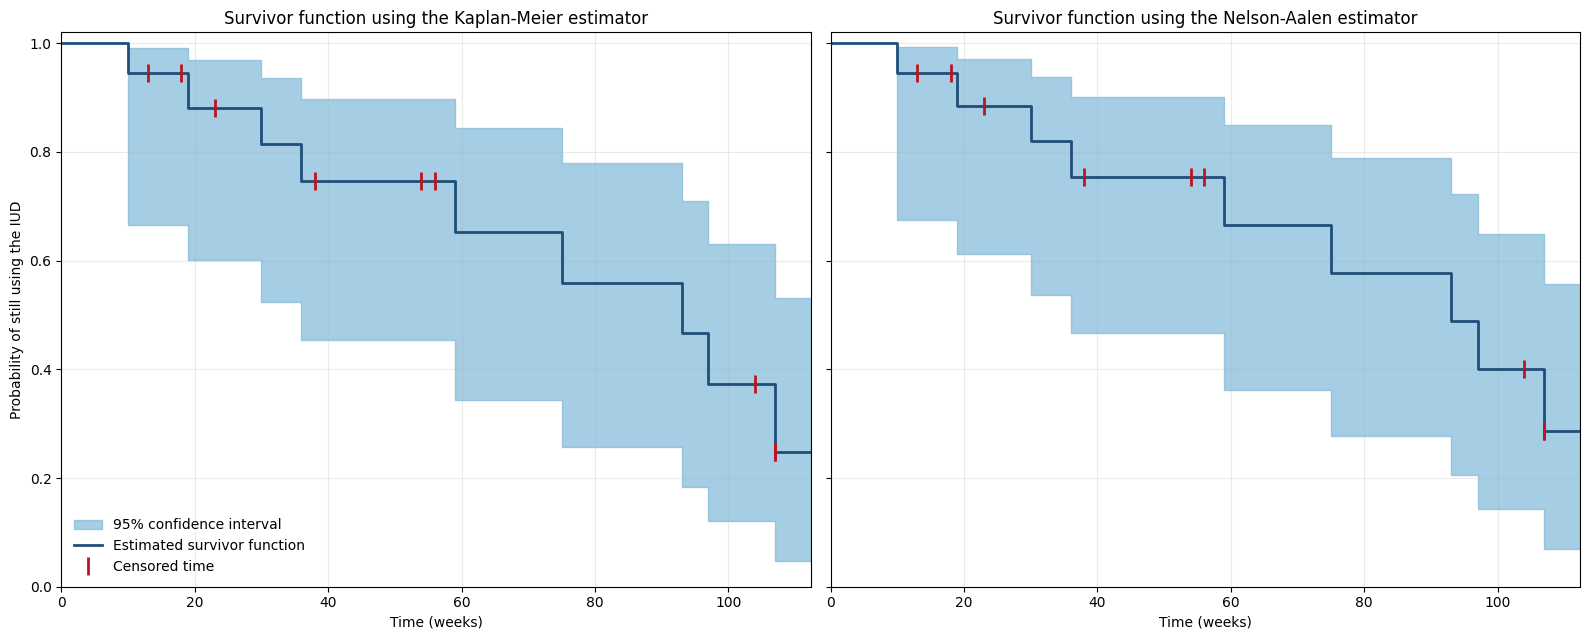

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), sharex=True, sharey=True)

for ax, datasurvivor, name in zip(axes, [DatKaplanMeier, DatNelsonAalen], ['Kaplan-Meier', 'Nelson-Aalen']):
    PlotStep(ax, datasurvivor, 'Survivor', label='Estimated survivor function')
    PlotCensored(ax, datasurvivor, DatOriginal)
    ax.set_xlabel('Time (weeks)')
    ax.set_title(f'Survivor function using the {name} estimator')
    ax.grid(True, alpha=0.25)

axes[0].set_ylabel('Probability of still using the IUD')
axes[0].set_xlim(0, T_END)
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc='lower left', frameon=False)
plt.tight_layout()

### Cumulative hazard function

The Nelson-Aalen estimate of the cumulative hazard is never larger than the Kaplan-Meier one, because $-\log(1-x)\geq x$.

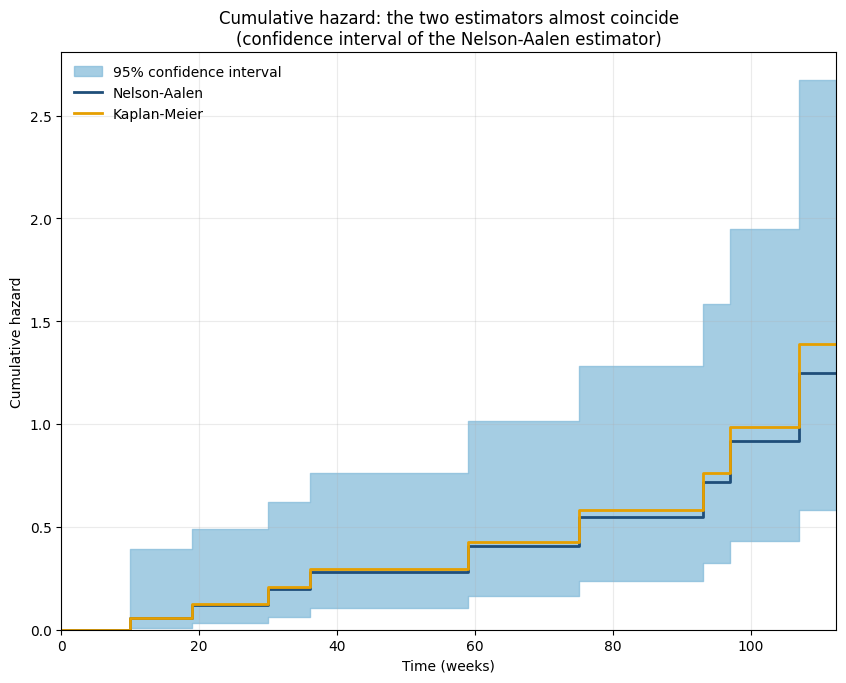

In [19]:
fig, ax = plt.subplots(figsize=(10, 7.5))

PlotStep(ax, DatNelsonAalen, 'CumHazard', label='Nelson-Aalen')
PlotStep(ax, DatKaplanMeier, 'CumHazard', color=opt_color, label='Kaplan-Meier', band=False)

ax.set_xlabel('Time (weeks)')
ax.set_ylabel('Cumulative hazard')
ax.set_xlim(0, T_END)
ax.set_ylim(0, None)
ax.set_title('Cumulative hazard: the two estimators almost coincide\n(confidence interval of the Nelson-Aalen estimator)')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

### Hazard function

The hazard is estimated as constant in each interval. The estimate is very irregular, since each interval has a single event. The last interval has no end, so the hazard cannot be estimated there.

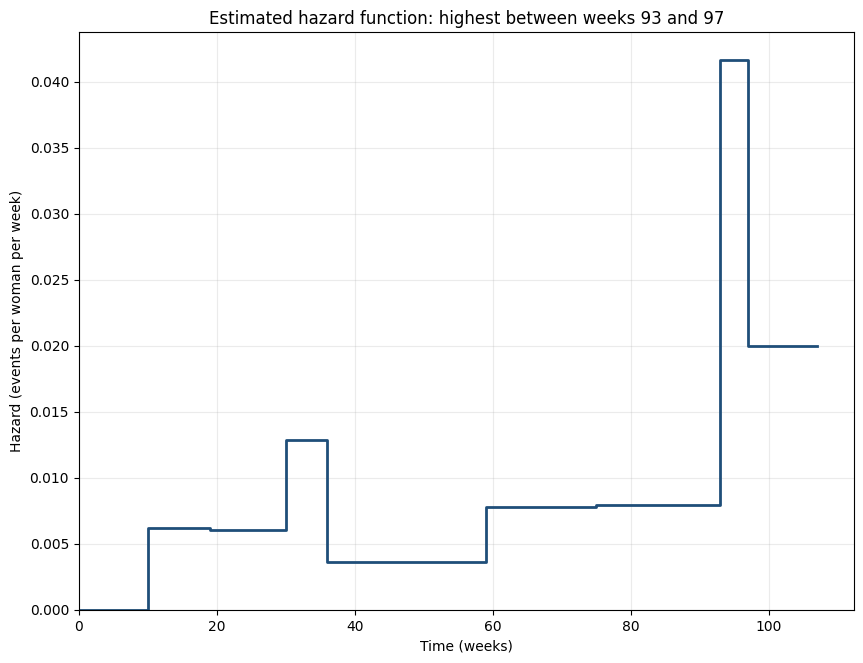

In [20]:
Finite = np.isfinite(DatKaplanMeier['tj+1'])

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.step(np.append(DatKaplanMeier.loc[Finite, 'tj'], DatKaplanMeier.loc[~Finite, 'tj']),
        np.append(DatKaplanMeier.loc[Finite, 'Hazard'], DatKaplanMeier.loc[Finite, 'Hazard'].iloc[-1]),
        where='post', color=line_color, lw=2)

ax.set_xlabel('Time (weeks)')
ax.set_ylabel('Hazard (events per woman per week)')
ax.set_xlim(0, T_END)
ax.set_ylim(0, None)
ax.set_title('Estimated hazard function: highest between weeks 93 and 97')
ax.grid(True, alpha=0.25)

## Quantile inference

The median time to discontinuation is the quantile of probability $p=0.5$.

In [21]:
InferenceQuantile(0.5, ALPHA, EPSILON, DatKaplanMeier)

,Prob.,Quantile,LowerQuantile,UpperQuantile
0,0.5,93,59.423747,126.576253


In [22]:
InferenceQuantile(0.5, ALPHA, EPSILON, DatNelsonAalen)

,Prob.,Quantile,LowerQuantile,UpperQuantile
0,0.5,93,58.495774,127.504226


The quantile is read from the survivor function: it is the first time at which the curve is below $1-p$. The times $\hat u$ and $\hat l$, used to estimate the density, are the ones where the curve crosses $1-p+\epsilon$ and $1-p-\epsilon$.

In [23]:
def PlotQuantile(ax, p, epsilon, legend=True):
    PlotStep(ax, DatKaplanMeier, 'Survivor', label='Kaplan-Meier estimator', band=False)
    ax.axhline(1-p, color='#333333', lw=1, ls='--', label=r'$1-p$')
    ax.axhspan(1-p-epsilon, 1-p+epsilon, color=ci_color, alpha=0.35, lw=0, label=r'$1-p\pm\epsilon$')
    try:
        quantile = InferenceQuantile(p, ALPHA, epsilon, DatKaplanMeier).loc[0]
        tp, lower, upper = quantile['Quantile'], quantile['LowerQuantile'], quantile['UpperQuantile']
        # The interval comes from a normal approximation and can start below zero; it is drawn from zero
        ax.plot([max(lower, 0), upper], [0, 0], color=opt_color, lw=7, solid_capstyle='butt', clip_on=False, zorder=5,
                label=ci_label)
        ax.vlines(tp, 0, 1-p, color=opt_color, lw=1.5, ls=':')
        ax.plot(tp, 0, 'o', color=opt_color, markersize=11, markeredgecolor='#333333', markeredgewidth=1.2,
                clip_on=False, zorder=6, label='Estimated quantile')
        ax.set_title(f'p = {p:.2f}: quantile {tp:.0f} weeks, interval ({lower:.0f}, {upper:.0f})')
    except ValueError:
        ax.set_title(f'p = {p:.2f}: the quantile or its interval cannot be estimated\n(try another p or a larger epsilon)')
    ax.set_xlabel('Time (weeks)')
    ax.set_ylabel('Probability of still using the IUD')
    ax.set_xlim(0, 1.3*T_END)
    ax.set_ylim(0, 1.02)
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper right', frameon=False)

Move the sliders to change the probability $p$ and the parameter $\epsilon$ (this cell needs a running kernel).

In [24]:
def interactive_quantile(p, epsilon):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    PlotQuantile(ax, p, epsilon)
    plt.show()

interact(interactive_quantile,
         p=FloatSlider(value=0.5, min=0.1, max=0.7, step=0.05, description='p'),
         epsilon=FloatSlider(value=EPSILON, min=0.01, max=0.2, step=0.01, description='epsilon'));

interactive(children=(FloatSlider(value=0.5, description='p', max=0.7, min=0.1, step=0.05), FloatSlider(value=…

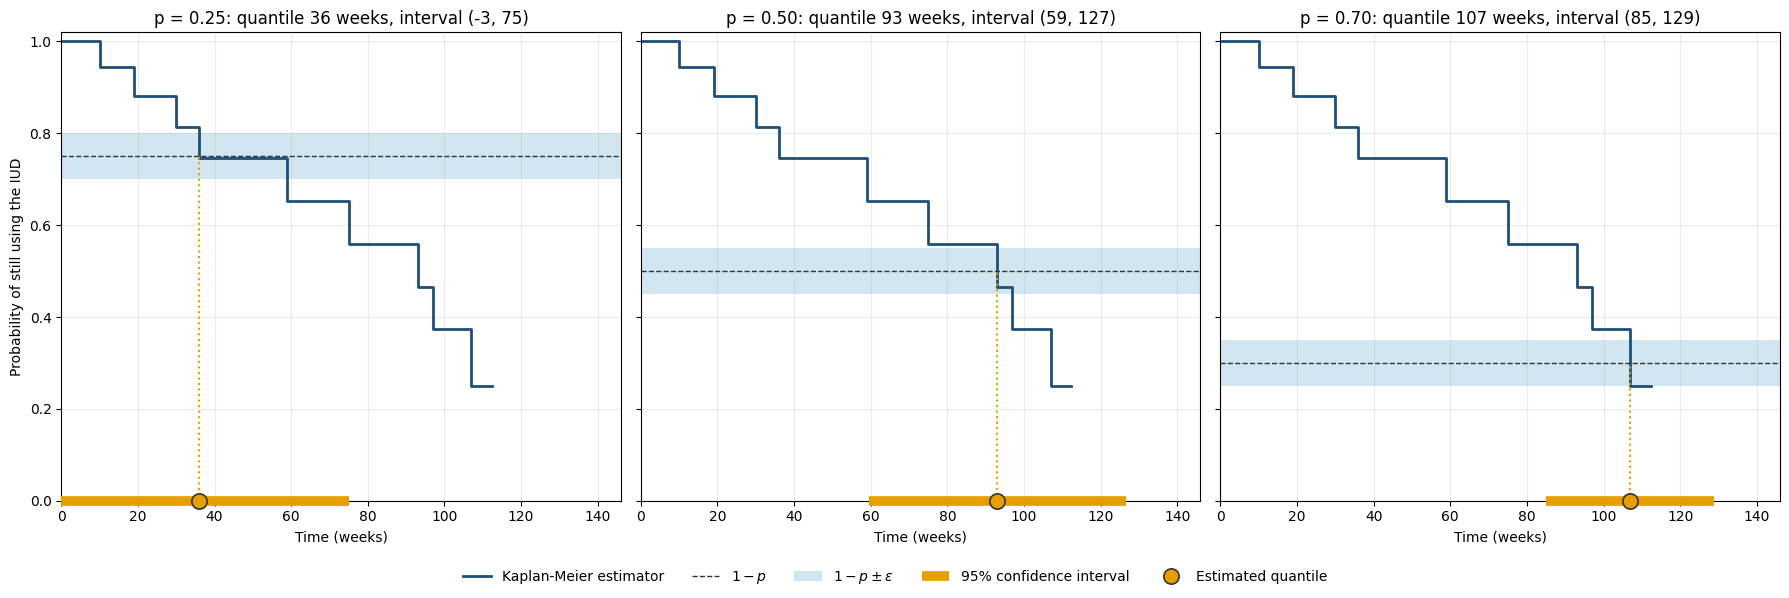

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, p in zip(axes, [0.25, 0.5, 0.7]):
    PlotQuantile(ax, p, EPSILON, legend=False)
for ax in axes[1:]:
    ax.set_ylabel('')
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))